### **Part 1: EDA**

In [12]:
import pandas as pd

df = pd.read_parquet('./tmdb_m1/movies_raw.parquet')

print(df.shape)
print(df.dtypes)
print(df.describe().round(2))
df.head()


(5455, 10)
genre_ids             object
id                     int64
title                 object
original_language     object
original_title        object
overview              object
popularity           float64
release_date          object
vote_average         float64
vote_count             int64
dtype: object
               id  popularity  vote_average  vote_count
count     5455.00     5455.00       5455.00     5455.00
mean    624632.78        8.32          6.40     1359.42
std     300136.31       16.85          0.81     2777.29
min       5492.00        0.43          2.90      100.00
25%     397091.50        3.20          5.89      180.50
50%     534490.00        4.89          6.40      378.00
75%     817703.00        8.46          6.96     1179.50
max    1699155.00      623.39          9.90    33380.00


,genre_ids,id,title,original_language,original_title,overview,popularity,release_date,vote_average,vote_count
0,[18],320367,Return,en,Return,A tale of terror. Cathy Reed has been institut...,0.8561,2015-01-01,6.600,1177
1,"[10749, 35]",313867,Roald Dahl's Esio Trot,en,Roald Dahl's Esio Trot,Retired bachelor Mr Hoppy is hopelessly in lov...,3.5595,2015-01-02,6.700,128
2,[27],299551,The Atticus Institute,en,The Atticus Institute,"In the early 1970s, Dr. Henry West creates an ...",3.5013,2015-01-05,5.759,373
3,"[28, 12, 14]",297291,The Scorpion King 4: Quest for Power,en,The Scorpion King 4: Quest for Power,"When he is betrayed by a trusted friend, Matha...",6.1805,2015-01-09,5.100,250
4,[27],309063,The Ouija Experiment 2: Theatre of Death,en,The Ouija Experiment 2: Theatre of Death,A fun filled weekend turns deadly when a group...,1.7502,2015-01-13,4.700,105


In [13]:
missing = df.isna().sum()
if missing[missing > 0].shape[0] == 0:
    print("No missing values found.")
else:
    print(missing[missing > 0])

No missing values found.


In [ ]:
print("Duplicate movie IDs:", df["id"].duplicated().sum())

# Checking empty strings in text columns
for column in ["title", "original_title", "overview", "release_date"]:
    blanks = df[column].str.strip().eq("")
    print(f"Blank {column}:", blanks.sum())

empty_genres = df["genre_ids"].str.len().eq(0)
print("Movies without genres:", empty_genres.sum())

df.loc[empty_genres, ["id", "title", "genre_ids"]]

Duplicate movie IDs: 0
Blank title: 0
Blank original_title: 0
Blank overview: 0
Blank release_date: 0
Movies without genres: 1


,id,title,genre_ids
4177,1140817,As,[]


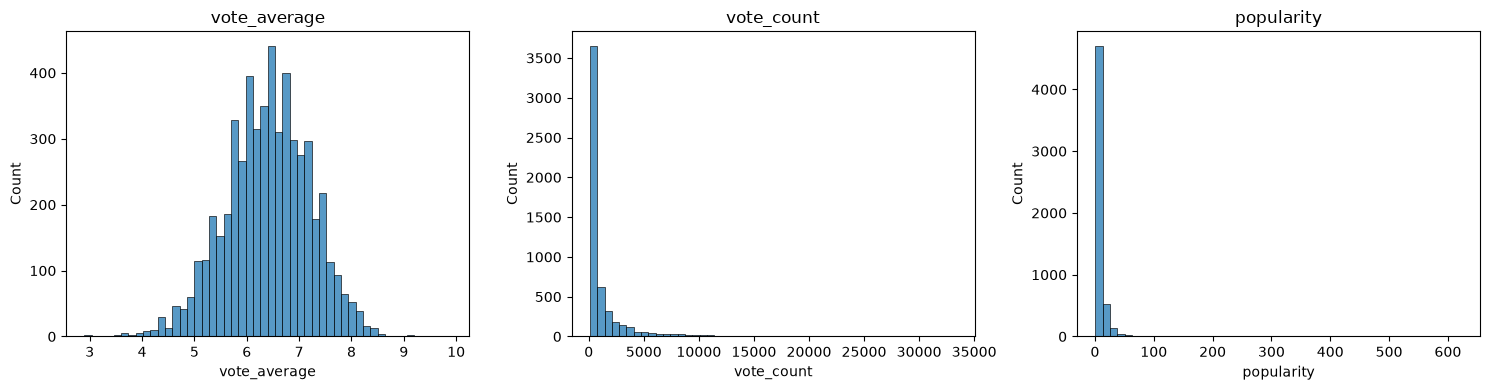

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, column in zip(
    axes, ["vote_average", "vote_count", "popularity"]
):
    sns.histplot(data=df, x=column, bins=50, ax=ax)
    ax.set_title(column)

plt.tight_layout()
plt.show()

### Distribution observations

- **Average ratings** are roughly bell-shaped around ~6.4, with most movies
  scoring between 5 and 8.
- **Vote counts** are strongly right-skewed: most movies have relatively
  few votes, while a small number have thousands. The minimum of 100
  reflects our acquisition scope.
- **Popularity** is also strongly right-skewed. A few high scores stretch
  the horizontal axis, making the main concentration very hard to distinguish.
  Popularity measures attention the movie is getting on TMDB rather than audience satisfaction.


In [18]:
for column in ["vote_average", "vote_count", "popularity"]:
    print(f"\nTop 5 by {column}:")
    display(
        df.nlargest(5, column)[
            ["title", "release_date", "vote_average", "vote_count", "popularity"]
        ]
    )


Top 5 by vote_average:


,title,release_date,vote_average,vote_count,popularity
4694,The Way to the Heart,2024-04-02,9.900,143,2.2230
1589,Nude,2017-10-29,9.327,171,7.3166
5408,Batman: Knightfall Part 1: Knightfall,2026-06-23,9.143,421,50.3488
5425,Avatar Aang: The Last Airbender,2026-07-24,9.129,1257,76.4733
5375,Swapped,2026-05-01,8.863,2224,47.8219



Top 5 by vote_count:


,title,release_date,vote_average,vote_count,popularity
591,Deadpool,2016-02-09,7.626,33380,30.6607
1825,Avengers: Infinity War,2018-04-25,8.245,33062,94.9992
2393,Avengers: Endgame,2019-04-24,8.245,28902,118.8549
2632,Joker,2019-10-01,8.100,28427,38.6163
146,Avengers: Age of Ultron,2015-04-22,7.279,25114,47.6682



Top 5 by popularity:


,title,release_date,vote_average,vote_count,popularity
5427,Spider-Man: Brand New Day,2026-07-29,7.900,3022,623.3942
5450,Resident Evil,2026-09-16,7.300,747,364.5221
5418,The Odyssey,2026-07-15,8.011,4013,322.0423
5447,Runner,2026-09-07,8.328,378,312.3985
5439,Coyote vs. Acme,2026-08-17,7.531,666,295.1815


### Observations from the top-five movies

- **Highest average ratings:** the top two movies have ratings of 9.900 and 9.327, based on only 143 and 171 votes. These averages describe a smaller set of voters than those of the most-voted movies; a high average does not mean broad popularity though!
- **Highest vote counts:** the five most-voted movies have average ratings between **7.279 and 8.245**, all above the overall sample mean of approximately **6.40**. They were released between 2015 and 2019 and have had more time to accumulate votes than recent releases. 
- **Highest popularity scores:** all five were released between **July and September 2026**, close to the acquisition cutoff of October 4, 2026. They have the highest **popularity scores**, not necessarily the highest audience ratings: their ratings range from **7.300 to 8.328**. This is consistent with attention being concentrated on recent releases in this snapshot.



### Validity and acquisition-scope checks

We check whether movie IDs are present and positive integers, ratings are within 0–10, vote counts are non-negative integers, popularity is non-negative, and release dates can be parsed.

Separately, we check again that the records match our acquisition scope: at least 100 votes, English as the original language, and release dates between January 1, 2015 and October 4, 2026. 


In [ ]:
dates = pd.to_datetime(
    df["release_date"], format="%Y-%m-%d", errors="coerce"
)

checks = pd.Series({
    "Missing movie IDs": df["id"].isna().sum(),
    "Non-positive movie IDs": (df["id"] <= 0).sum(),
    "Non-integer movie IDs": (df["id"] % 1 != 0).sum(),

    "Ratings outside 0–10": (~df["vote_average"].between(0, 10)).sum(),
    "Negative vote counts": (df["vote_count"] < 0).sum(),
    "Non-integer vote counts": (df["vote_count"] % 1 != 0).sum(),
    "Negative popularity": (df["popularity"] < 0).sum(),

    "Missing or unparseable release dates": dates.isna().sum(),
    "Vote counts below 100": (df["vote_count"] < 100).sum(),
    "Non-English original language": df["original_language"].ne("en").sum(),
    "Release dates outside our scope": (
        dates.notna()
        & ~dates.between("2015-01-01", "2026-10-04")
    ).sum(),
})

print(checks)

Missing movie IDs                       0
Non-positive movie IDs                  0
Non-integer movie IDs                   0
Ratings outside 0–10                    0
Negative vote counts                    0
Non-integer vote counts                 0
Negative popularity                     0
Missing or unparseable release dates    0
Vote counts below 100                   0
Non-English original language           0
Release dates outside our scope         0
dtype: int64


### Validity and scope observations

No violations were found in the tested ID, numeric, date, or acquisition-scope rules.

release_date
2015    541
2016    560
2017    574
2018    570
2019    526
2020    466
2021    469
2022    471
2023    423
2024    371
2025    318
2026    166
Name: count, dtype: int64


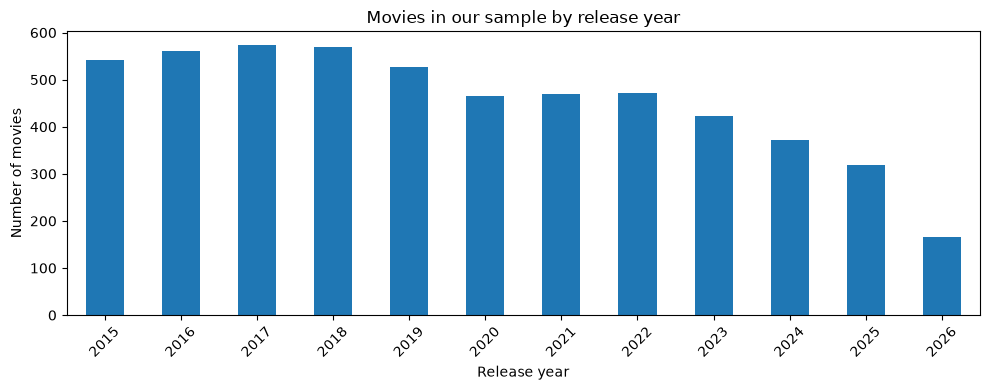

In [21]:
movies_per_year = dates.dt.year.value_counts().sort_index()

print(movies_per_year)

movies_per_year.plot.bar(figsize=(10, 4))
plt.title("Movies in our sample by release year")
plt.xlabel("Release year")
plt.ylabel("Number of movies")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

              vote_average  vote_count  popularity
vote_average         1.000       0.283       0.216
vote_count           0.283       1.000       0.303
popularity           0.216       0.303       1.000


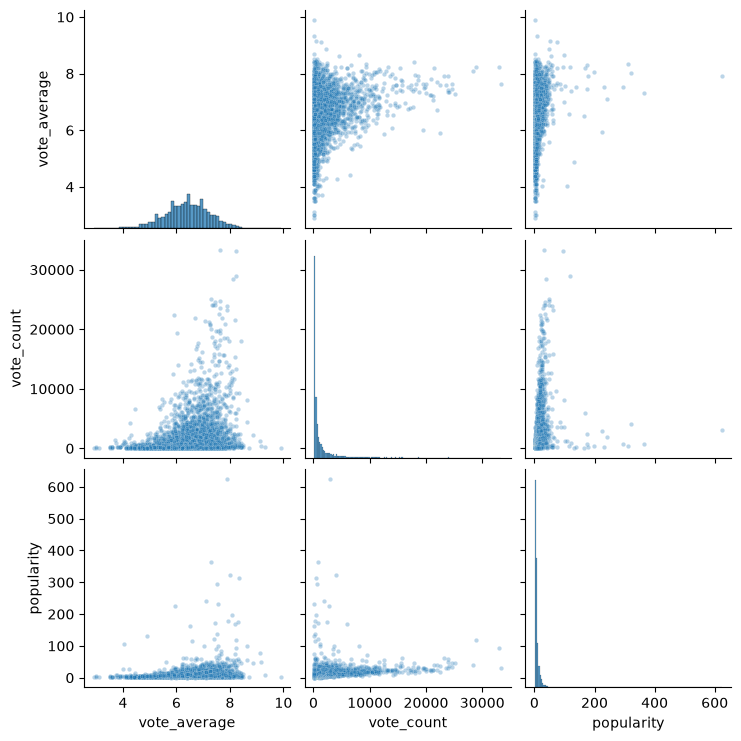

In [22]:
columns = ["vote_average", "vote_count", "popularity"]

print(df[columns].corr().round(3))

sns.pairplot(df[columns], plot_kws={"alpha": 0.3, "s": 10})
plt.show()

### Numeric relationship observations

The Pearson correlations are positive but relatively weak: **0.283** between average rating and vote count, **0.216** between average rating and popularity, and **0.303** between vote count and popularity.

The scatterplots show substantial spread. A few large vote counts and popularity scores stretch the axes, making most movies appear clustered near the lower end.

No strong linear relationship is visible.

### Exploring the genres parquet!

genre_name
Drama              2080
Comedy             1668
Thriller           1588
Action             1165
Horror             1152
Adventure           692
Science Fiction     690
Crime               689
Romance             669
Mystery             555
Family              552
Fantasy             494
Animation           470
Documentary         308
History             285
TV Movie            226
Music               208
War                 137
Western              69
Name: movie_id, dtype: int64


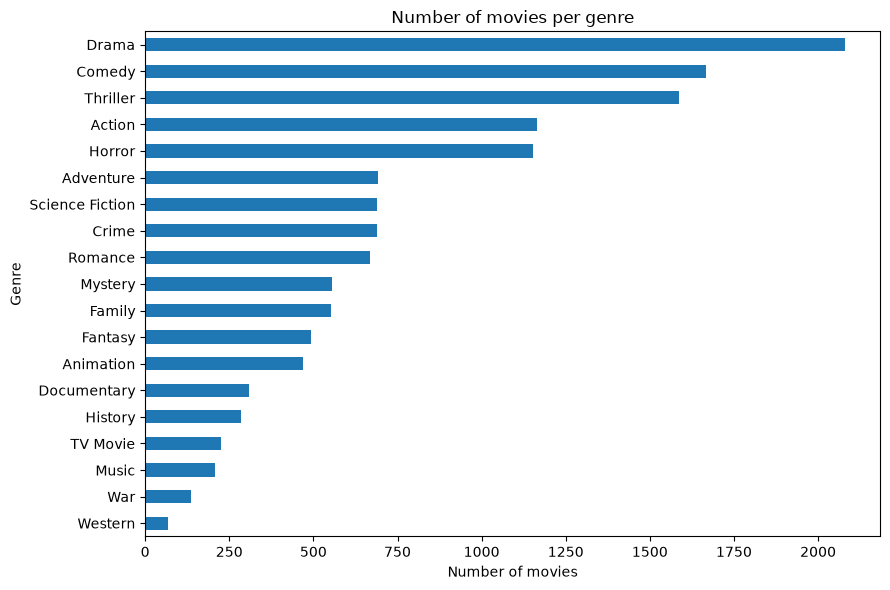

In [25]:
genres = pd.read_parquet("./tmdb_m1/movie_genres.parquet")

genre_counts = (
    genres.groupby("genre_name")["movie_id"]
    .nunique()
    .sort_values(ascending=False)
)

print(genre_counts)

genre_counts.sort_values().plot.barh(figsize=(9, 6))
plt.title("Number of movies per genre")
plt.xlabel("Number of movies")
plt.ylabel("Genre")
plt.tight_layout()
plt.show()

In [26]:
print("Shape:", genres.shape)
print("\nTypes:\n", genres.dtypes)
print("\nMissing values:\n", genres.isna().sum())

print("\nDuplicate movie–genre pairs:",
      genres.duplicated(["movie_id", "genre_id"]).sum())

print("Genre rows referencing absent movies:",
      (~genres["movie_id"].isin(df["id"])).sum())

Shape: (13697, 3)

Types:
 movie_id       int64
genre_id       int64
genre_name    object
dtype: object

Missing values:
 movie_id      0
genre_id      0
genre_name    0
dtype: int64

Duplicate movie–genre pairs: 0
Genre rows referencing absent movies: 0


genre_ids
0       1
1     913
2    1848
3    1928
4     551
5     188
6      22
7       4
Name: count, dtype: int64


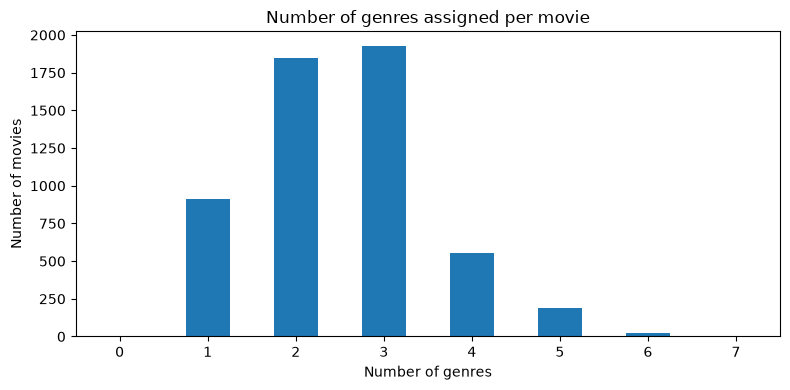

In [27]:
genres_per_movie = df["genre_ids"].str.len()

print(genres_per_movie.value_counts().sort_index())

genres_per_movie.value_counts().sort_index().plot.bar(figsize=(8, 4))
plt.title("Number of genres assigned per movie")
plt.xlabel("Number of genres")
plt.ylabel("Number of movies")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [28]:
expected = (
    df[["id", "genre_ids"]]
    .explode("genre_ids")
    .dropna(subset=["genre_ids"])
)

expected_pairs = set(
    expected[["id", "genre_ids"]].itertuples(index=False, name=None)
)

actual_pairs = set(
    genres[["movie_id", "genre_id"]].itertuples(index=False, name=None)
)

print("Associations missing from genre table:",
      len(expected_pairs - actual_pairs))

print("Unexpected associations in genre table:",
      len(actual_pairs - expected_pairs))

Associations missing from genre table: 0
Unexpected associations in genre table: 0


In [29]:
names_per_id = genres.groupby("genre_id")["genre_name"].nunique()

print("Genre IDs mapped to multiple names:",
      (names_per_id > 1).sum())

print("Blank genre names:",
      genres["genre_name"].str.strip().eq("").sum())

display(
    genres[["genre_id", "genre_name"]]
    .drop_duplicates()
    .sort_values("genre_id")
    .reset_index(drop=True)
)

Genre IDs mapped to multiple names: 0
Blank genre names: 0


,genre_id,genre_name
0,12,Adventure
1,14,Fantasy
2,16,Animation
3,18,Drama
4,27,Horror
5,28,Action
6,35,Comedy
7,36,History
8,37,Western
9,53,Thriller


## General exploration summary

### Movies table
- The dataset contains **5,455 movies and 10 columns**.
- No pandas-detected nulls, duplicate movie IDs, or blank values in the checked text columns were found.
- **One movie, As (ID 1140817), has an empty genre list.**
- The tested ID, numeric, release-date, or acquisition-scope rules were all adequate and respected.
- Average ratings are roughly bell-shaped around **6.4**, ranging from **2.9 to 9.9**.
- Vote counts and popularity are strongly right-skewed. Their maxima are **33,380 votes** and **623.39**, compared with medians of **378** and **4.89**.
- Pearson correlations are positive and relatively weak: **0.283** for rating–vote count, **0.216** for rating–popularity, and **0.303** for vote count–popularity. Large values stretch the scatterplot axes and compress the main concentration of movies.

### Movie–genre table
- The table contains **13,697 movie–genre associations, 3 columns, and 19 distinct genres**.
- No nulls, blank genre names, duplicate movie–genre pairs.
- Each genre ID maps to one name, and the associations match the movies table's genre lists exactly.
- **Drama** has the most movies (**2,080**), while **Western** has the fewest (**69**).
- Most movies have **2 or 3 genres**: **1,848** and **1,928** movies respectively. Four movies have seven genres, and one has none.
- Movies may belong to several genres, so genre counts overlap and do not sum to the number of movies.



### **Part 2: Cleaning**

In [30]:

clean = df.copy()

clean_genres = genres.copy()

DECISIONS = []

clean["release_date"] = pd.to_datetime(clean["release_date"], format="%Y-%m-%d", errors="coerce")

DECISIONS.append((
    "Convert release_date to datetime",
    "Enable date operations; all dates passed parsing checks",
    len(clean)
))

clean["missing_genre"] = clean["genre_ids"].str.len().eq(0)
DECISIONS.append((
    "Flag missing genre",
    "Preserve movies with incomplete genre metadata",
    int(clean["missing_genre"].sum())
))

print("Movies:", clean.shape)
print("Genre associations:", clean_genres.shape)
display(clean.loc[clean["missing_genre"], ["id", "title", "missing_genre"]])

Movies: (5455, 11)
Genre associations: (13697, 3)


,id,title,missing_genre
4177,1140817,As,True


In [31]:
decisions_table = pd.DataFrame(
    DECISIONS,
    columns=["What", "Why", "Rows affected"]
)

display(decisions_table)

print(f"Movies: {len(df)} before → {len(clean)} after")
print(f"Genre associations: {len(genres)} before → {len(clean_genres)} after")
print("Missing genres flagged:", clean["missing_genre"].sum())
print("Release date type:", clean["release_date"].dtype)

,What,Why,Rows affected
0,Convert release_date to datetime,Enable date operations; all dates passed parsi...,5455
1,Flag missing genre,Preserve movies with incomplete genre metadata,1


Movies: 5455 before → 5455 after
Genre associations: 13697 before → 13697 after
Missing genres flagged: 1
Release date type: datetime64[ns]


In [32]:
assert len(clean) == len(df)
assert clean["id"].is_unique
assert pd.api.types.is_datetime64_any_dtype(clean["release_date"])
assert clean["release_date"].notna().all()
assert clean["missing_genre"].equals(clean["genre_ids"].str.len().eq(0))
pd.testing.assert_frame_equal(clean_genres, genres)

clean.to_parquet("movies_clean.parquet", index=False)
clean_genres.to_parquet("movie_genres_clean.parquet", index=False)

print("Cleaned Parquet files saved.")

Cleaned Parquet files saved.
